# Pendulum with electrical energy generation

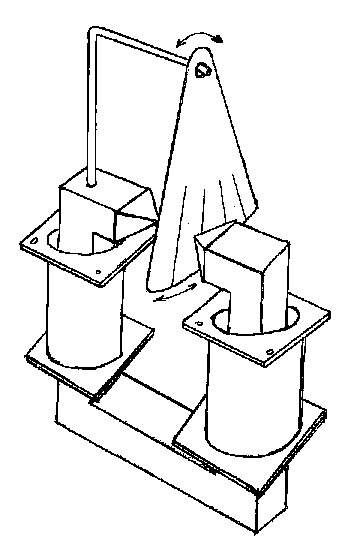

In [173]:
# Checking and installing Pint only if necessary
try:
    import pint
except ImportError:
    !pip install pint
    import pint

# Importing libraries
import numpy as np
import matplotlib.pyplot as plt


In [174]:
# Creating a unit manager
ureg = pint.UnitRegistry()

# Constant mu0
MU0 = 4 * np.pi * 1e-7 * ureg.henry / ureg.meter

# Magnetomotive force of the pendulum
# Define function to calculate the magnetomotive force
def pendulum_magnetomotive_force(ni, w, t):
    return ni * np.sin(w * t)

In [175]:
# Length of the air gap and the iron core
air_gap_length = 0.5 * ureg.cm
iron_length = 30 * ureg.cm

# Area of the iron core
iron_area = (2 * ureg.cm) * (2 * ureg.cm)
iron_area

<Quantity(4, 'centimeter ** 2')>

In [176]:
# Pendulum
ni = 500e3 * ureg.A
w = 2 * np.pi * ureg.rad / ureg.s
t = np.linspace(0, 2, 10000, endpoint=False) * ureg.s
fmm_pendulum = pendulum_magnetomotive_force(ni, w, t)
fmm_pendulum

Magnitude,[0.0 628.3183653511627 1256.6357385018632 ... -1884.9511272529792 -1256.6357385023855 -628.3183653515462]
Units,ampere


In [177]:
# Air reluctance
air_reluctance = (1 / MU0) * (iron_length / iron_area)
air_reluctance = air_reluctance.to('A/Wb')
air_reluctance

<Quantity(5.96831037e+08, 'ampere / weber')>

In [178]:
# Magnetic flux
magnetic_flux = fmm_pendulum / air_reluctance
magnetic_flux

Magnitude,[0.0 1.052757525708139e-06 2.105513388968447e-06 ... -3.1582659273353383e-06 -2.105513388969322e-06 -1.0527575257087814e-06]
Units,weber


In [179]:
# Induced voltage
coil_turns = 1000
induced_voltage = -coil_turns * np.gradient(magnetic_flux, t)
induced_voltage

Magnitude,[-5.263787628540694 -5.263783472421117 -5.263771004068951 ... -5.263750223501905 -5.263771004066973 -5.263779316303283]
Units,weber/second


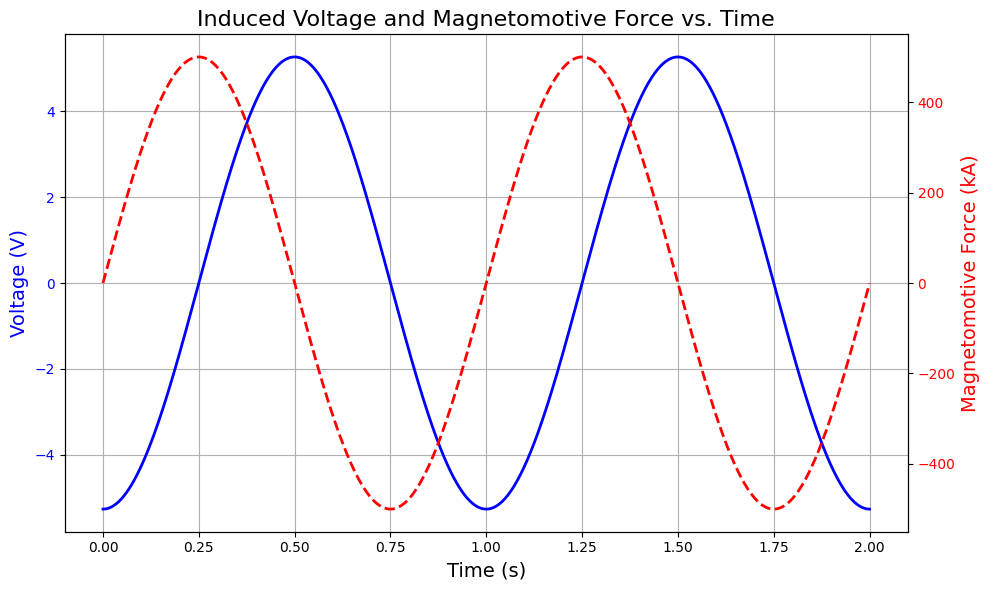

In [180]:
# Plotting the induced voltage and magnetomotive force
fig, ax1 = plt.subplots(figsize=(10, 6))

# Primary y-axis: Induced voltage
ax1.plot(t, induced_voltage, label='Induced Voltage', color='blue', linewidth=2)
ax1.set_xlabel('Time (s)', fontsize=14)
ax1.set_ylabel('Voltage (V)', fontsize=14, color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.grid(True)

# Secondary y-axis: Magnetomotive force
ax2 = ax1.twinx()
ax2.plot(t, fmm_pendulum/1e3, label='Magnetomotive Force', color='red', linewidth=2, linestyle='--')
ax2.set_ylabel('Magnetomotive Force (kA)', fontsize=14, color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Adding title and adjusting layout
plt.title('Induced Voltage and Magnetomotive Force vs. Time', fontsize=16)
fig.tight_layout()
plt.show()